In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import chart_studio.plotly as py
import plotly.graph_objs as go
from plotly.offline import iplot, init_notebook_mode
import cufflinks
cufflinks.go_offline()
cufflinks.set_config_file(world_readable=True, theme='pearl')
from sklearn.model_selection import train_test_split
from sklearn import metrics
from math import sqrt
import requests
from sklearn.metrics import mean_squared_error, r2_score

In [93]:
df=pd.read_csv('Air_Quality.csv',parse_dates = ["Date"])
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,NaN,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,NaN,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,NaN,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,NaN,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,NaN,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25550,Thiruvananthapuram,2020-04-06,16.88,31.28,4.32,10.18,13.71,5.55,0.32,4.24,30.17,NaN,NaN,NaN,59.0,Satisfactory
25551,Thiruvananthapuram,2020-04-07,18.57,35.34,5.70,9.56,12.70,4.97,0.46,6.00,34.58,NaN,NaN,NaN,53.0,Satisfactory
25552,Thiruvananthapuram,2020-04-08,18.85,37.62,5.44,8.86,12.09,4.39,0.47,5.79,51.56,NaN,NaN,NaN,61.0,Satisfactory
25553,Thiruvananthapuram,2020-04-09,19.06,45.18,3.37,7.91,9.92,4.37,0.52,5.76,46.01,NaN,NaN,NaN,63.0,Satisfactory


In [94]:
print(df.isnull().sum())

City              0
Date              0
PM2.5          4255
PM10          10702
NO             4509
NO2            3159
NOx            4021
NH3            9785
CO             1999
SO2            3499
O3             3510
Benzene        5122
Toluene        7409
Xylene        16417
AQI            4251
AQI_Bucket     4251
dtype: int64


In [95]:
(df.isnull().sum()/df.shape[0]*100).sort_values(ascending=False)

Xylene        64.241831
PM10          41.878302
NH3           38.289963
Toluene       28.992369
Benzene       20.043044
NO            17.644297
PM2.5         16.650362
AQI           16.634709
AQI_Bucket    16.634709
NOx           15.734690
O3            13.735081
SO2           13.692037
NO2           12.361573
CO             7.822344
Date           0.000000
City           0.000000
dtype: float64

In [96]:
df.describe()

,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,25555,21300.000000,14853.000000,21046.000000,22396.000000,21534.000000,15770.000000,23556.000000,22056.000000,22045.000000,20433.000000,18146.000000,9138.000000,21304.000000
mean,2018-03-02 15:37:01.702211072,72.824121,127.653183,17.658008,29.481695,33.835887,25.667720,2.466555,15.097498,34.430208,3.324202,9.148687,3.224390,177.582473
min,2015-01-01 00:00:00,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,2017-02-02 00:00:00,32.157500,62.340000,5.900000,12.197500,13.422500,9.342500,0.530000,5.570000,19.010000,0.130000,0.730000,0.120000,85.000000
50%,2018-05-25 00:00:00,53.090000,102.770000,9.950000,22.340000,24.570000,18.185000,0.930000,9.120000,30.880000,0.980000,2.930000,0.840000,126.000000
75%,2019-05-30 00:00:00,87.210000,161.180000,19.717500,38.430000,42.167500,33.050000,1.520000,15.610000,45.430000,2.850000,8.987500,3.370000,230.000000
max,2020-04-10 00:00:00,949.990000,1000.000000,351.300000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000
std,NaN,67.356092,94.974574,22.539144,25.278898,32.688813,27.379991,7.499295,19.299535,21.411852,16.887308,21.316590,6.726918,147.398293


In [97]:
df['Date'] = pd.to_datetime(df['Date'])
df.rename(columns = {'AQI_Bucket':'Air_quality'}, inplace = True)
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,Air_quality
0,Ahmedabad,2015-01-01,NaN,NaN,NaN,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,NaN,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,NaN,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,NaN,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,NaN,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [98]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25555 entries, 0 to 25554
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   City         25555 non-null  object        
 1   Date         25555 non-null  datetime64[ns]
 2   PM2.5        21300 non-null  float64       
 3   PM10         14853 non-null  float64       
 4   NO           21046 non-null  float64       
 5   NO2          22396 non-null  float64       
 6   NOx          21534 non-null  float64       
 7   NH3          15770 non-null  float64       
 8   CO           23556 non-null  float64       
 9   SO2          22056 non-null  float64       
 10  O3           22045 non-null  float64       
 11  Benzene      20433 non-null  float64       
 12  Toluene      18146 non-null  float64       
 13  Xylene       9138 non-null   float64       
 14  AQI          21304 non-null  float64       
 15  Air_quality  21304 non-null  object        
dtypes: d

# Feature Enginnering

In [99]:
# identify duplicate rows
duplicate_rows = df[df.duplicated()]
print(duplicate_rows)


Empty DataFrame
Columns: [City, Date, PM2.5, PM10, NO, NO2, NOx, NH3, CO, SO2, O3, Benzene, Toluene, Xylene, AQI, Air_quality]
Index: []


In [100]:
# count the number of duplicates
num_duplicates = df.duplicated().sum()
print(num_duplicates)

0


In [101]:
# For calculating the AQI we will replace all the NaN values of columns PM2.5, PM10, NO, NO2, NOx,
# NH3, CO, SO2, O3, Benzene, Toluene, Xylene with the mean values

cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
df[cols] = df[cols].fillna(df[cols].mean())
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,Air_quality
0,Ahmedabad,2015-01-01,72.824121,127.653183,17.658008,18.22,17.15,25.66772,0.92,27.64,133.36,0.000000,0.020000,0.00000,NaN,NaN
1,Ahmedabad,2015-01-02,72.824121,127.653183,17.658008,15.69,16.46,25.66772,0.97,24.55,34.06,3.680000,5.500000,3.77000,NaN,NaN
2,Ahmedabad,2015-01-03,72.824121,127.653183,17.658008,19.30,29.70,25.66772,17.40,29.07,30.70,6.800000,16.400000,2.25000,NaN,NaN
3,Ahmedabad,2015-01-04,72.824121,127.653183,17.658008,18.48,17.97,25.66772,1.70,18.59,36.08,4.430000,10.140000,1.00000,NaN,NaN
4,Ahmedabad,2015-01-05,72.824121,127.653183,17.658008,21.42,37.76,25.66772,22.10,39.33,39.31,7.010000,18.890000,2.78000,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25550,Thiruvananthapuram,2020-04-06,16.880000,31.280000,4.320000,10.18,13.71,5.55000,0.32,4.24,30.17,3.324202,9.148687,3.22439,59.0,Satisfactory
25551,Thiruvananthapuram,2020-04-07,18.570000,35.340000,5.700000,9.56,12.70,4.97000,0.46,6.00,34.58,3.324202,9.148687,3.22439,53.0,Satisfactory
25552,Thiruvananthapuram,2020-04-08,18.850000,37.620000,5.440000,8.86,12.09,4.39000,0.47,5.79,51.56,3.324202,9.148687,3.22439,61.0,Satisfactory
25553,Thiruvananthapuram,2020-04-09,19.060000,45.180000,3.370000,7.91,9.92,4.37000,0.52,5.76,46.01,3.324202,9.148687,3.22439,63.0,Satisfactory


## We cannot fill null values of AQI with mean or mode nor we can delete it, So, we will calculate AQI from all 7 measures:
The AQI calculation uses 7 measures: PM2.5, PM10, SO2, NOx, NH3, CO and O3.
> For PM2.5, PM10, SO2, NOx and NH3 the average value in last 24-hrs is used with the condition of having at least 16 values.

> For CO and O3 the maximum value in last 8-hrs is used.

> Each measure is converted into a Sub-Index based on pre-defined groups.

> Sometimes measures are not available due to lack of measuring or lack of required data points.

> Final AQI is the maximum Sub-Index with the condition that at least one of PM2.5 and PM10 should be available and at least three out of the seven should be available.

## calculating Sub-Index

In [102]:
# PM10 Sub-Index calculation
def get_PM10_subindex(x):
    if x <= 50:
        return x
    elif x > 50 and x <= 100:
        return x
    elif x > 100 and x <= 250:
        return 100 + (x - 100) * 100 / 150
    elif x > 250 and x <= 350:
        return 200 + (x - 250)
    elif x > 350 and x <= 430:
        return 300 + (x - 350) * 100 / 80
    elif x > 430:
        return 400 + (x - 430) * 100 / 80
    else:
        return 0

df["PM10_SubIndex"] = df["PM10"].astype(int).apply(lambda x: get_PM10_subindex(x))
    
# PM2.5 Sub-Index calculation
def get_PM25_subindex(x):
    if x <= 30:
        return x * 50 / 30
    elif x > 30 and x <= 60:
        return 50 + (x - 30) * 50 / 30
    elif x > 60 and x <= 90:
        return 100 + (x - 60) * 100 / 30
    elif x > 90 and x <= 120:
        return 200 + (x - 90) * 100 / 30
    elif x > 120 and x <= 250:
        return 300 + (x - 120) * 100 / 130
    elif x > 250:
        return 400 + (x - 250) * 100 / 130
    else:
        return 0

df["PM2.5_SubIndex"] = df["PM2.5"].astype(int).apply(lambda x: get_PM25_subindex(x))


# SO2 Sub-Index calculation
def get_SO2_subindex(x):
    if x <= 40:
        return x * 50 / 40
    elif x > 40 and x <= 80:
        return 50 + (x - 40) * 50 / 40
    elif x > 80 and x <= 380:
        return 100 + (x - 80) * 100 / 300
    elif x > 380 and x <= 800:
        return 200 + (x - 380) * 100 / 420
    elif x > 800 and x <= 1600:
        return 300 + (x - 800) * 100 / 800
    elif x > 1600:
        return 400 + (x - 1600) * 100 / 800
    else:
        return 0

df["SO2_SubIndex"] = df["SO2"].astype(int).apply(lambda x: get_SO2_subindex(x))

# NOx Sub-Index calculation
def get_NOx_subindex(x):
    if x <= 40:
        return x * 50 / 40
    elif x > 40 and x <= 80:
        return 50 + (x - 40) * 50 / 40
    elif x > 80 and x <= 180:
        return 100 + (x - 80) * 100 / 100
    elif x > 180 and x <= 280:
        return 200 + (x - 180) * 100 / 100
    elif x > 280 and x <= 400:
        return 300 + (x - 280) * 100 / 120
    elif x > 400:
        return 400 + (x - 400) * 100 / 120
    else:
        return 0

df["NOx_SubIndex"] = df["NOx"].astype(int).apply(lambda x: get_NOx_subindex(x))

# NH3 Sub-Index calculation
def get_NH3_subindex(x):
    if x <= 200:
        return x * 50 / 200
    elif x > 200 and x <= 400:
        return 50 + (x - 200) * 50 / 200
    elif x > 400 and x <= 800:
        return 100 + (x - 400) * 100 / 400
    elif x > 800 and x <= 1200:
        return 200 + (x - 800) * 100 / 400
    elif x > 1200 and x <= 1800:
        return 300 + (x - 1200) * 100 / 600
    elif x > 1800:
        return 400 + (x - 1800) * 100 / 600
    else:
        return 0

df["NH3_SubIndex"] = df["NH3"].astype(int).apply(lambda x: get_NH3_subindex(x))

# CO Sub-Index calculation
def get_CO_subindex(x):
    if x <= 1:
        return x * 50 / 1
    elif x > 1 and x <= 2:
        return 50 + (x - 1) * 50 / 1
    elif x > 2 and x <= 10:
        return 100 + (x - 2) * 100 / 8
    elif x > 10 and x <= 17:
        return 200 + (x - 10) * 100 / 7
    elif x > 17 and x <= 34:
        return 300 + (x - 17) * 100 / 17
    elif x > 34:
        return 400 + (x - 34) * 100 / 17
    else:
        return 0

df["CO_SubIndex"] = df["CO"].astype(int).apply(lambda x: get_CO_subindex(x))

# O3 Sub-Index calculation
def get_O3_subindex(x):
    if x <= 50:
        return x * 50 / 50
    elif x > 50 and x <= 100:
        return 50 + (x - 50) * 50 / 50
    elif x > 100 and x <= 168:
        return 100 + (x - 100) * 100 / 68
    elif x > 168 and x <= 208:
        return 200 + (x - 168) * 100 / 40
    elif x > 208 and x <= 748:
        return 300 + (x - 208) * 100 / 539
    elif x > 748:
        return 400 + (x - 400) * 100 / 539
    else:
        return 0

df["O3_SubIndex"] = df["O3"].astype(int).apply(lambda x: get_O3_subindex(x))

In [103]:
if pd.isna(df["AQI"]).any():
        df["AQI"] = df["AQI"].fillna(round(df[["PM2.5_SubIndex", "PM10_SubIndex", "SO2_SubIndex", "NOx_SubIndex","NH3_SubIndex", "CO_SubIndex", "O3_SubIndex"]].max(axis = 1)))
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,...,Xylene,AQI,Air_quality,PM10_SubIndex,PM2.5_SubIndex,SO2_SubIndex,NOx_SubIndex,NH3_SubIndex,CO_SubIndex,O3_SubIndex
0,Ahmedabad,2015-01-01,72.824121,127.653183,17.658008,18.22,17.15,25.66772,0.92,27.64,...,0.00000,149.0,NaN,118.0,140.000000,33.75,21.25,6.25,0.000000,148.529412
1,Ahmedabad,2015-01-02,72.824121,127.653183,17.658008,15.69,16.46,25.66772,0.97,24.55,...,3.77000,140.0,NaN,118.0,140.000000,30.00,20.00,6.25,0.000000,34.000000
2,Ahmedabad,2015-01-03,72.824121,127.653183,17.658008,19.30,29.70,25.66772,17.40,29.07,...,2.25000,300.0,NaN,118.0,140.000000,36.25,36.25,6.25,300.000000,30.000000
3,Ahmedabad,2015-01-04,72.824121,127.653183,17.658008,18.48,17.97,25.66772,1.70,18.59,...,1.00000,140.0,NaN,118.0,140.000000,22.50,21.25,6.25,50.000000,36.000000
4,Ahmedabad,2015-01-05,72.824121,127.653183,17.658008,21.42,37.76,25.66772,22.10,39.33,...,2.78000,329.0,NaN,118.0,140.000000,48.75,46.25,6.25,329.411765,39.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25550,Thiruvananthapuram,2020-04-06,16.880000,31.280000,4.320000,10.18,13.71,5.55000,0.32,4.24,...,3.22439,59.0,Satisfactory,31.0,26.666667,5.00,16.25,1.25,0.000000,30.000000
25551,Thiruvananthapuram,2020-04-07,18.570000,35.340000,5.700000,9.56,12.70,4.97000,0.46,6.00,...,3.22439,53.0,Satisfactory,35.0,30.000000,7.50,15.00,1.00,0.000000,34.000000
25552,Thiruvananthapuram,2020-04-08,18.850000,37.620000,5.440000,8.86,12.09,4.39000,0.47,5.79,...,3.22439,61.0,Satisfactory,37.0,30.000000,6.25,15.00,1.00,0.000000,51.000000
25553,Thiruvananthapuram,2020-04-09,19.060000,45.180000,3.370000,7.91,9.92,4.37000,0.52,5.76,...,3.22439,63.0,Satisfactory,45.0,31.666667,6.25,11.25,1.00,0.000000,46.000000


In [104]:
# Now for removing NaN values of Air_quality we use AQI category

# Now for removing NaN values of Air_quality we use AQI category

# from IPython import display
# display.Image("https://w.ndtvimg.com/sites/3/2019/12/18122812/air_pollution_standards_cpcb.png", width=...)

In [105]:
if pd.isna(df["Air_quality"]).any():
        def get_Air_quality(x):
            if x <= 50:
                return "Good"
            elif x > 50 and x <= 100:
                return "Satisfactory"
            elif x > 100 and x <= 200:
                return "Moderate"
            elif x > 200 and x <= 300:
                return "Poor"
            elif x > 300 and x <= 400:
                return "Very Poor"
            elif x > 400:
                return "Severe"
            else:
                return '0'

        df["Air_quality"] = df["Air_quality"].fillna(df["AQI"].apply(lambda x: get_Air_quality(x)))
        
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,...,Xylene,AQI,Air_quality,PM10_SubIndex,PM2.5_SubIndex,SO2_SubIndex,NOx_SubIndex,NH3_SubIndex,CO_SubIndex,O3_SubIndex
0,Ahmedabad,2015-01-01,72.824121,127.653183,17.658008,18.22,17.15,25.66772,0.92,27.64,...,0.00000,149.0,Moderate,118.0,140.000000,33.75,21.25,6.25,0.000000,148.529412
1,Ahmedabad,2015-01-02,72.824121,127.653183,17.658008,15.69,16.46,25.66772,0.97,24.55,...,3.77000,140.0,Moderate,118.0,140.000000,30.00,20.00,6.25,0.000000,34.000000
2,Ahmedabad,2015-01-03,72.824121,127.653183,17.658008,19.30,29.70,25.66772,17.40,29.07,...,2.25000,300.0,Poor,118.0,140.000000,36.25,36.25,6.25,300.000000,30.000000
3,Ahmedabad,2015-01-04,72.824121,127.653183,17.658008,18.48,17.97,25.66772,1.70,18.59,...,1.00000,140.0,Moderate,118.0,140.000000,22.50,21.25,6.25,50.000000,36.000000
4,Ahmedabad,2015-01-05,72.824121,127.653183,17.658008,21.42,37.76,25.66772,22.10,39.33,...,2.78000,329.0,Very Poor,118.0,140.000000,48.75,46.25,6.25,329.411765,39.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25550,Thiruvananthapuram,2020-04-06,16.880000,31.280000,4.320000,10.18,13.71,5.55000,0.32,4.24,...,3.22439,59.0,Satisfactory,31.0,26.666667,5.00,16.25,1.25,0.000000,30.000000
25551,Thiruvananthapuram,2020-04-07,18.570000,35.340000,5.700000,9.56,12.70,4.97000,0.46,6.00,...,3.22439,53.0,Satisfactory,35.0,30.000000,7.50,15.00,1.00,0.000000,34.000000
25552,Thiruvananthapuram,2020-04-08,18.850000,37.620000,5.440000,8.86,12.09,4.39000,0.47,5.79,...,3.22439,61.0,Satisfactory,37.0,30.000000,6.25,15.00,1.00,0.000000,51.000000
25553,Thiruvananthapuram,2020-04-09,19.060000,45.180000,3.370000,7.91,9.92,4.37000,0.52,5.76,...,3.22439,63.0,Satisfactory,45.0,31.666667,6.25,11.25,1.00,0.000000,46.000000


In [106]:
# Remove the PM10_SubIndex, PM2.5_SubIndex, SO2_SubIndex, NOx_SubIndex, NH3_SubIndex, CO_SubIndex, and O3_SubIndex columns
# because now they are of no use for further process.
df = df.drop(columns=["PM10_SubIndex", "PM2.5_SubIndex", "SO2_SubIndex", "NOx_SubIndex", "NH3_SubIndex", "CO_SubIndex", "O3_SubIndex"])
df

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,Air_quality
0,Ahmedabad,2015-01-01,72.824121,127.653183,17.658008,18.22,17.15,25.66772,0.92,27.64,133.36,0.000000,0.020000,0.00000,149.0,Moderate
1,Ahmedabad,2015-01-02,72.824121,127.653183,17.658008,15.69,16.46,25.66772,0.97,24.55,34.06,3.680000,5.500000,3.77000,140.0,Moderate
2,Ahmedabad,2015-01-03,72.824121,127.653183,17.658008,19.30,29.70,25.66772,17.40,29.07,30.70,6.800000,16.400000,2.25000,300.0,Poor
3,Ahmedabad,2015-01-04,72.824121,127.653183,17.658008,18.48,17.97,25.66772,1.70,18.59,36.08,4.430000,10.140000,1.00000,140.0,Moderate
4,Ahmedabad,2015-01-05,72.824121,127.653183,17.658008,21.42,37.76,25.66772,22.10,39.33,39.31,7.010000,18.890000,2.78000,329.0,Very Poor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25550,Thiruvananthapuram,2020-04-06,16.880000,31.280000,4.320000,10.18,13.71,5.55000,0.32,4.24,30.17,3.324202,9.148687,3.22439,59.0,Satisfactory
25551,Thiruvananthapuram,2020-04-07,18.570000,35.340000,5.700000,9.56,12.70,4.97000,0.46,6.00,34.58,3.324202,9.148687,3.22439,53.0,Satisfactory
25552,Thiruvananthapuram,2020-04-08,18.850000,37.620000,5.440000,8.86,12.09,4.39000,0.47,5.79,51.56,3.324202,9.148687,3.22439,61.0,Satisfactory
25553,Thiruvananthapuram,2020-04-09,19.060000,45.180000,3.370000,7.91,9.92,4.37000,0.52,5.76,46.01,3.324202,9.148687,3.22439,63.0,Satisfactory


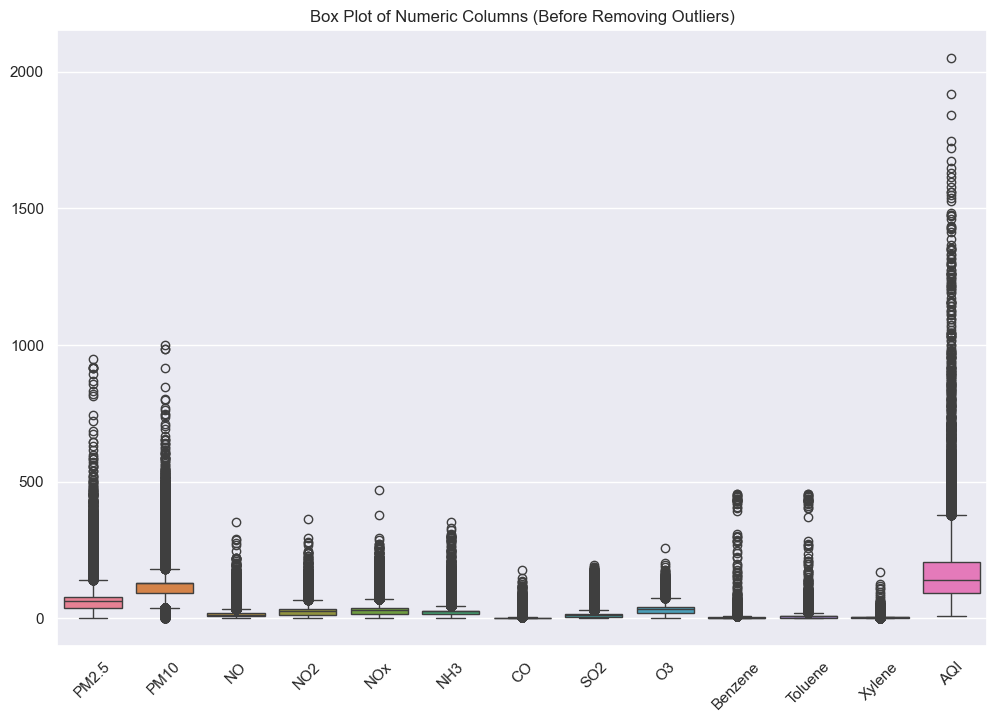

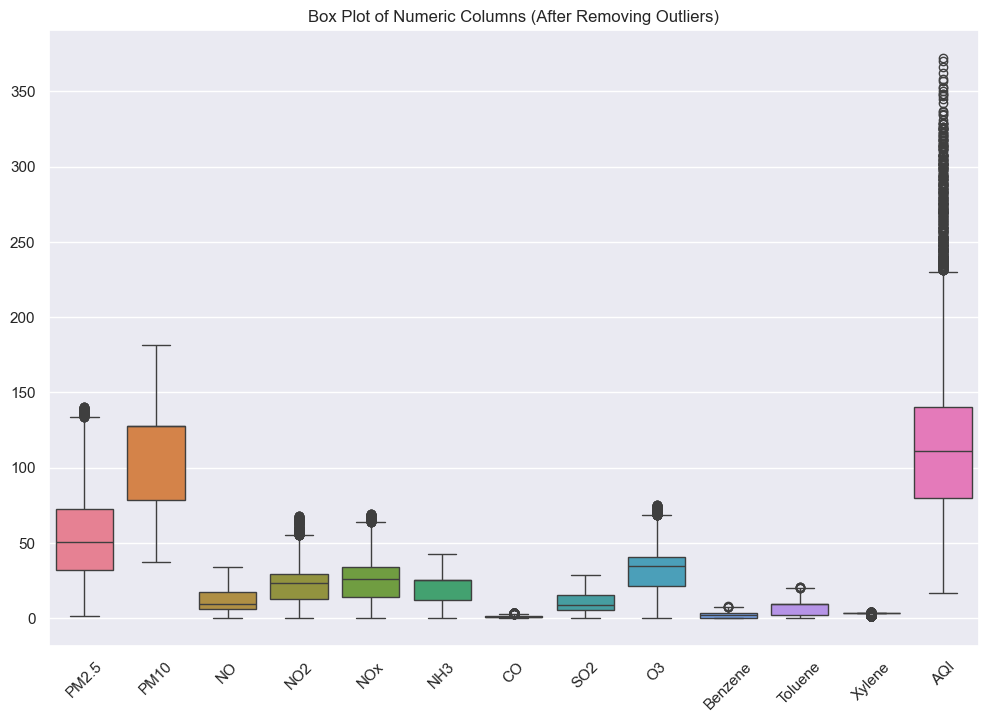

In [107]:
# Select numeric columns for outlier visualization
numeric_columns = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI']

# Create a box plot for each numeric column before removing outliers
plt.figure(figsize=(12, 8))
sns.boxplot(data=df[numeric_columns])
plt.xticks(rotation=45)
plt.title('Box Plot of Numeric Columns (Before Removing Outliers)')
plt.show()

# Remove outliers from the dataset
Q1 = df[numeric_columns].quantile(0.25)
Q3 = df[numeric_columns].quantile(0.75)
IQR = Q3 - Q1
df_cleaned = df[~((df[numeric_columns] < (Q1 - 1.5 * IQR)) | (df[numeric_columns] > (Q3 + 1.5 * IQR))).any(axis=1)]

# Create a box plot for each numeric column after removing outliers
plt.figure(figsize=(12, 8))
sns.boxplot(data=df_cleaned[numeric_columns])
plt.xticks(rotation=45)
plt.title('Box Plot of Numeric Columns (After Removing Outliers)')
plt.show()


# Exploratory Data Analysis


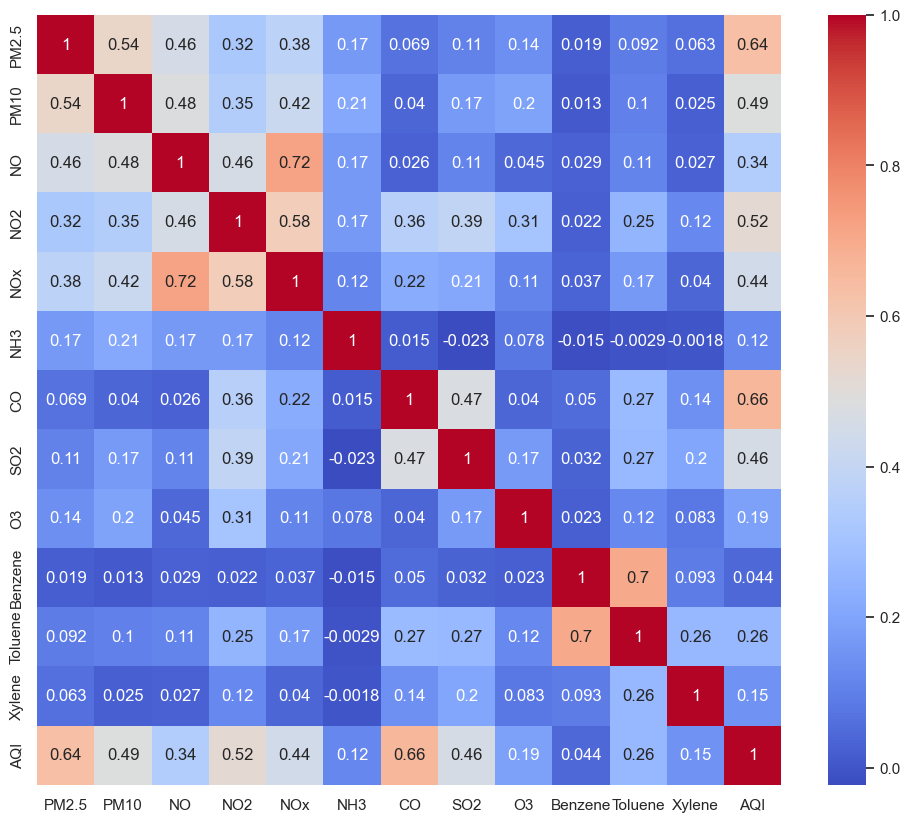

In [108]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', annot=True);

In [109]:
#segregating dates into months and years

df['Month']=df.Date.dt.month.astype(str)
df['Year']=df.Date.dt.year.astype(str)

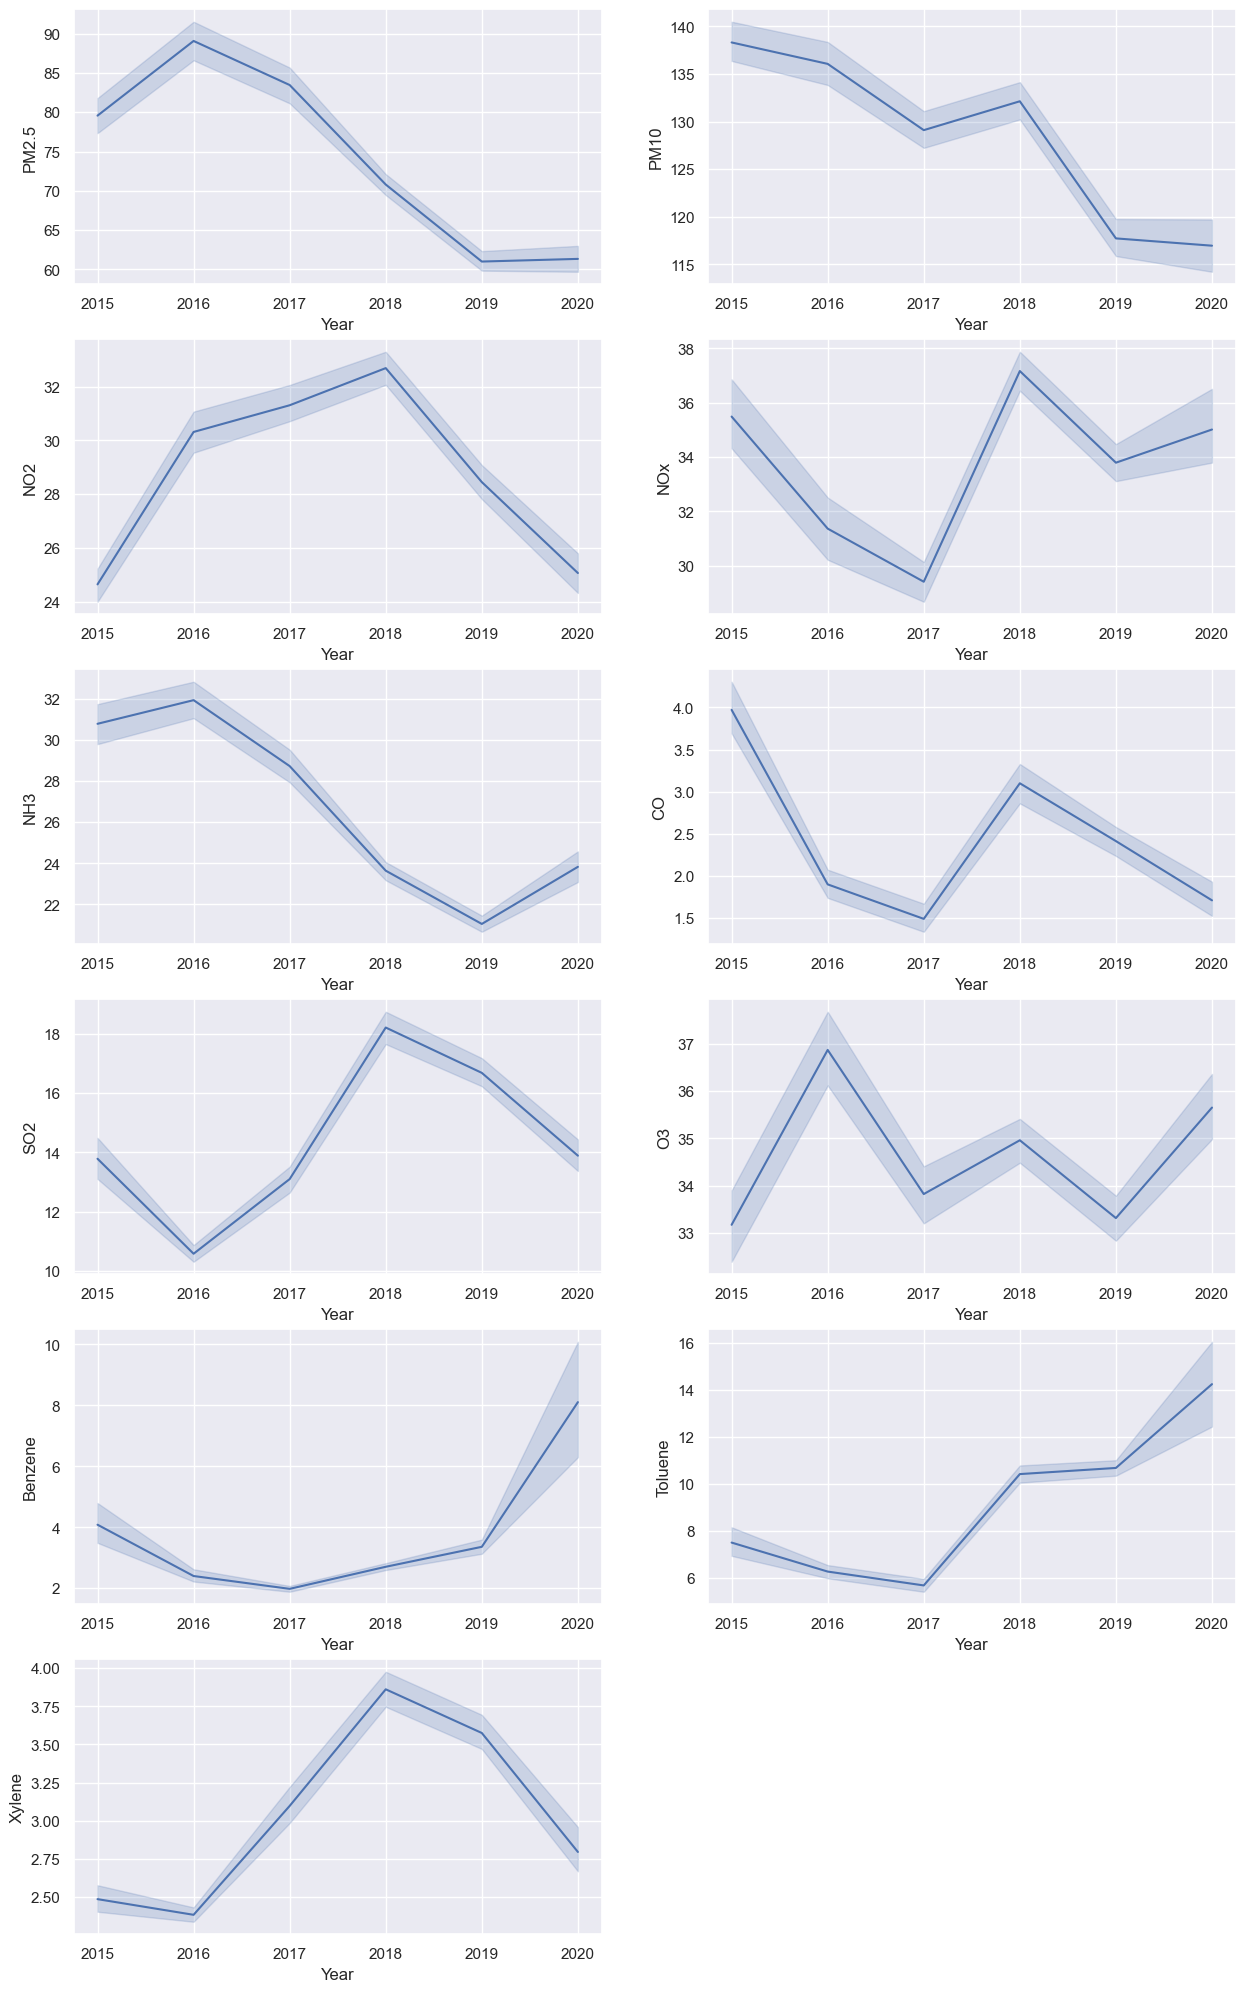

In [110]:
#line plot analysis for amount of particulate matter and gases  over the years
cols=['PM2.5','PM10','NO2','NOx','NH3',
      'CO','SO2','O3','Benzene','Toluene','Xylene']

x=df.iloc[:,2:]
fig=plt.figure(figsize=(15,25))
for i,col  in enumerate(cols):
    fig.add_subplot(6,2,i+1)
    sns.lineplot(x='Year',y=col,data=x)

### Here I divide the data set into two part namely Vehicular Pollution content (PM2.5, PM10, NO2, NH3, CO,) and Industrial Pollution content (CO, SO2, O3, Benzene, Toluene, Xylene) and find how these contents correlated with AQI (air quality index)

In [111]:
df2 = df.copy()
df2['Vehicular_Pollution_content'] = df2['PM2.5']+df2['PM10']+df2['NO']+df2['NO2']+df2['NOx']+df2['NH3']+df2['CO']
df2['Industrial_Pollution_content'] = df2['SO2']+df2['O3']+df2['Benzene']+df2['Toluene']+df2['Xylene']
df2 = df2.drop(['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3','Benzene','Toluene','Xylene'],axis=1)
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25555 entries, 0 to 25554
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   City                          25555 non-null  object        
 1   Date                          25555 non-null  datetime64[ns]
 2   AQI                           25555 non-null  float64       
 3   Air_quality                   25555 non-null  object        
 4   Month                         25555 non-null  object        
 5   Year                          25555 non-null  object        
 6   Vehicular_Pollution_content   25555 non-null  float64       
 7   Industrial_Pollution_content  25555 non-null  float64       
dtypes: datetime64[ns](1), float64(3), object(4)
memory usage: 1.6+ MB


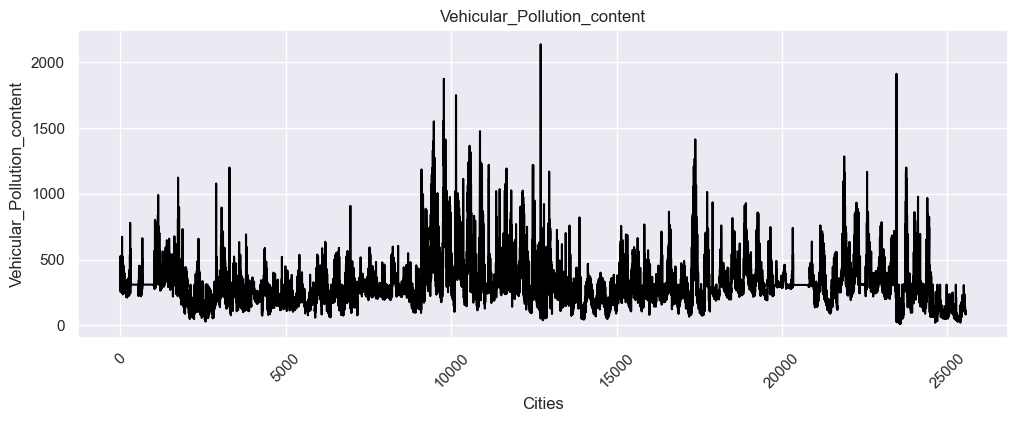

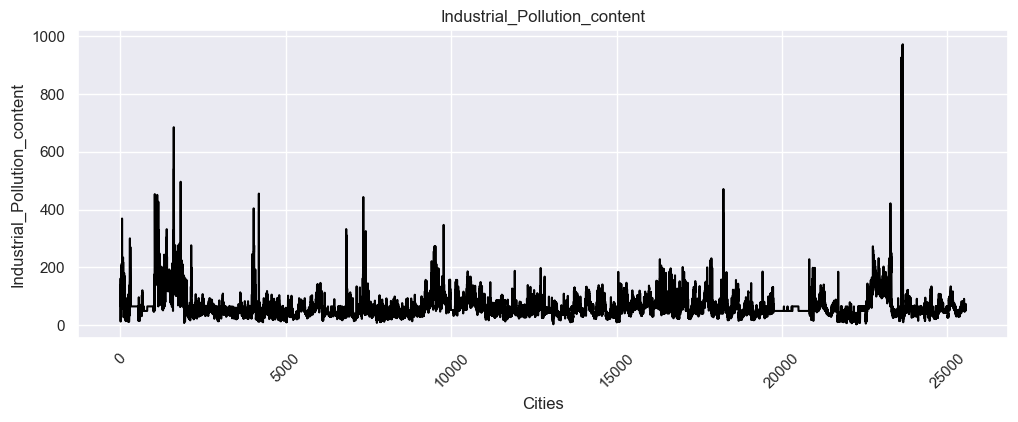

In [112]:
def ploting(var):
    plt.figure(figsize=(12, 4))
    df2[var].plot(kind='line', color='black', title=var)
    plt.xlabel('Cities')
    plt.ylabel(var)
    plt.xticks(rotation=45)
    plt.show()

ploting('Vehicular_Pollution_content')
ploting('Industrial_Pollution_content')

In [113]:
import plotly.express as px

def max_bar_plot(var):
    x1 = df2[['City', var]].groupby(["City"]).median().sort_values(by=var, ascending=True).tail(10).reset_index()
    fig = px.bar(
        x1,
        x='City',
        y=var,
        title=f'Most polluted cities ({var})',
        labels={'City': 'Cities', var: var}
    )
    fig.update_traces(marker_line_color='black', marker_line_width=1)
    fig.show()
    return fig

p1 = max_bar_plot('Industrial_Pollution_content')
p2 = max_bar_plot('Vehicular_Pollution_content')

In [114]:
import plotly.express as px

def min_bar_plot(var):
    x1 = df2[['City', var]].groupby(["City"]).mean().sort_values(by=var, ascending=True).head(10).reset_index()
    fig = px.bar(
        x1,
        x='City',
        y=var,
        title=f'Minimum polluted cities ({var})',
        labels={'City': 'Cities', var: var}
    )
    fig.update_traces(marker_line_color='black', marker_line_width=1)
    fig.show()
    return fig

p1 = min_bar_plot('Industrial_Pollution_content')
p2 = min_bar_plot('Vehicular_Pollution_content')

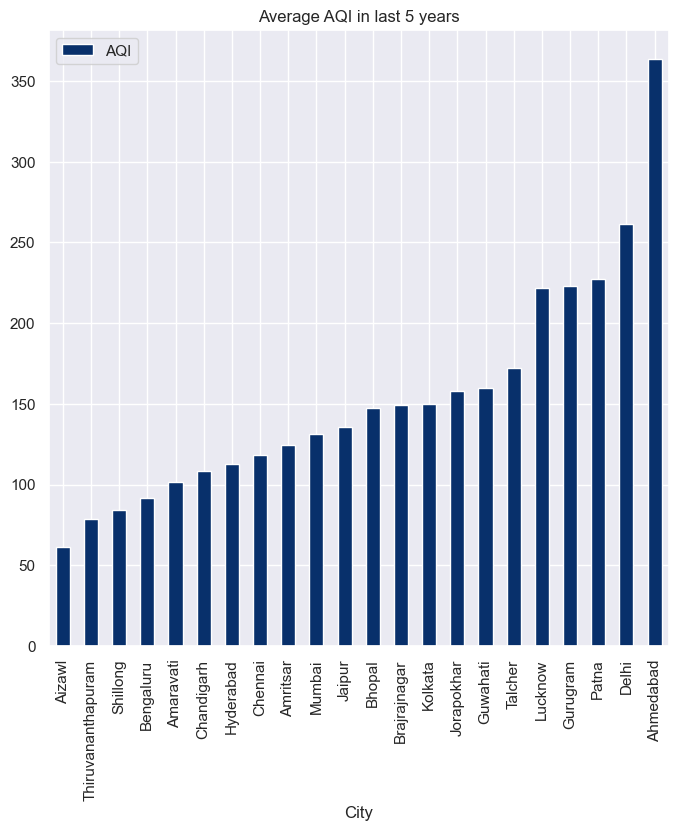

In [115]:
df[['City','AQI']].groupby('City').mean().sort_values('AQI').plot(kind='bar',cmap='Blues_r',figsize=(8,8))
plt.title('Average AQI in last 5 years');

### From above heatmap we observe a strong correlation of NO with NOx and of Benzene with Toluene so lets visualize them with the help of scatterplots¶


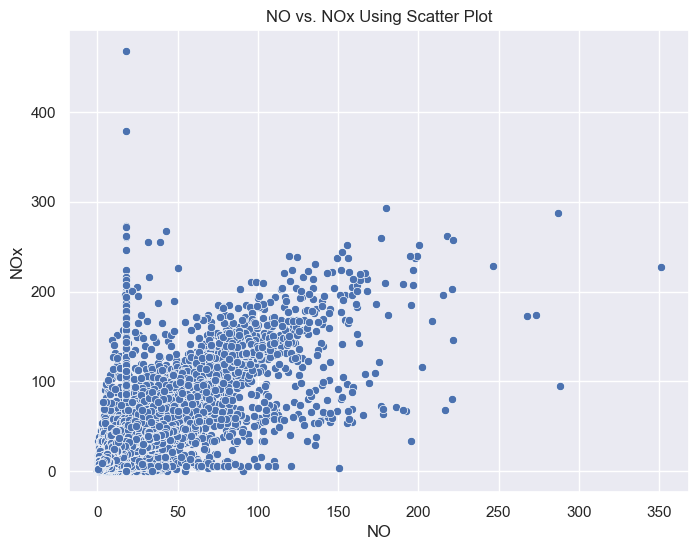

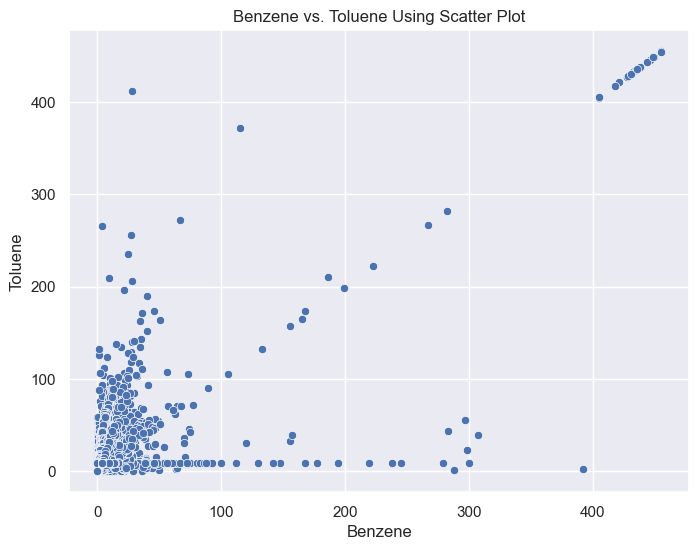

In [116]:
sns.set(rc={'figure.figsize': (8, 6)})
# plt.figure(figsize=(12, 6))
plt.figure(figsize=(8, 6))
sns.scatterplot(x='NO', y='NOx', data=df)
plt.title('NO vs. NOx Using Scatter Plot')
plt.show()

sns.scatterplot(x='Benzene', y='Toluene', data=df)
plt.title('Benzene vs. Toluene Using Scatter Plot')
plt.show()

# MODEL TRAINING

In [117]:
df = df.drop(columns = ['Date', 'Month', 'Year', 'City'], axis=1)
df

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,Air_quality
0,72.824121,127.653183,17.658008,18.22,17.15,25.66772,0.92,27.64,133.36,0.000000,0.020000,0.00000,149.0,Moderate
1,72.824121,127.653183,17.658008,15.69,16.46,25.66772,0.97,24.55,34.06,3.680000,5.500000,3.77000,140.0,Moderate
2,72.824121,127.653183,17.658008,19.30,29.70,25.66772,17.40,29.07,30.70,6.800000,16.400000,2.25000,300.0,Poor
3,72.824121,127.653183,17.658008,18.48,17.97,25.66772,1.70,18.59,36.08,4.430000,10.140000,1.00000,140.0,Moderate
4,72.824121,127.653183,17.658008,21.42,37.76,25.66772,22.10,39.33,39.31,7.010000,18.890000,2.78000,329.0,Very Poor
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25550,16.880000,31.280000,4.320000,10.18,13.71,5.55000,0.32,4.24,30.17,3.324202,9.148687,3.22439,59.0,Satisfactory
25551,18.570000,35.340000,5.700000,9.56,12.70,4.97000,0.46,6.00,34.58,3.324202,9.148687,3.22439,53.0,Satisfactory
25552,18.850000,37.620000,5.440000,8.86,12.09,4.39000,0.47,5.79,51.56,3.324202,9.148687,3.22439,61.0,Satisfactory
25553,19.060000,45.180000,3.370000,7.91,9.92,4.37000,0.52,5.76,46.01,3.324202,9.148687,3.22439,63.0,Satisfactory


## Train-Test Split:

In [118]:
y = df["AQI"]
x = df[['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2','O3', 'Benzene', 'Toluene', 'Xylene']]

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.25,random_state=0)
print(x_train.shape,x_test.shape,y_train.shape,y_test.shape)

(19166, 12) (6389, 12) (19166,) (6389,)


# Supervised Learning:

In [119]:
# Importing all Models.
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# 1. Linear Regression:

In [120]:
# Linear Regression Model
mreg = LinearRegression()
mreg.fit(x_train,y_train)
mlr_y_predict = mreg.predict(x_test)

# 2. Polynomial Regression:

In [121]:
# Polynomial Regression Model:
# Degree = 2

poly_reg = PolynomialFeatures(degree = 2)
preg = LinearRegression()
pf = poly_reg.fit_transform(x_train)
preg.fit(pf,y_train)
pr_y_predict = preg.predict(poly_reg.fit_transform(x_test))

# 3. Decision Tree:

In [122]:
# Decision Tree Tegression Model:

dec_tree = DecisionTreeRegressor(random_state = 0)
dec_tree.fit(x_train,y_train)
dt_y_predict = dec_tree.predict(x_test)

# 4. Random Forest:

In [123]:
# Random Forest Regression Model
# Random Forest with 500 trees

rt_reg = RandomForestRegressor(n_estimators = 500, random_state = 0)
rt_reg.fit(x_train,y_train)
rt_y_predict = rt_reg.predict(x_test)

# Model Evaluation: (Supervised Learning)

In [124]:
# Error Estimation Methods

# Test Data prediction

#----- Multiple Linear Regresion -------
rmse_mlr = sqrt(metrics.mean_squared_error(y_test, mlr_y_predict))
mae_mlr = metrics.mean_absolute_error(y_test, mlr_y_predict)
r2_mlr = metrics.r2_score(y_test,mlr_y_predict)

#----- Polynomial Regression ------------ 
rmse_pr = sqrt(metrics.mean_squared_error(y_test, pr_y_predict))
mae_pr = metrics.mean_absolute_error(y_test, pr_y_predict)
r2_pr = metrics.r2_score(y_test,pr_y_predict)

#----- Decision Tree Regression ---------
rmse_dt = sqrt(metrics.mean_squared_error(y_test, dt_y_predict))
mae_dt = metrics.mean_absolute_error(y_test, dt_y_predict)
r2_dt = metrics.r2_score(y_test,dt_y_predict)

#----- Random Forest Regression ---------
rmse_rt = sqrt(metrics.mean_squared_error(y_test, rt_y_predict))
mae_rt = metrics.mean_absolute_error(y_test, rt_y_predict)
r2_rt = metrics.r2_score(y_test,rt_y_predict)


# Training Data Prediction

#----- multiple linear regresion -------
mlr_ytp_rmse = sqrt(metrics.mean_squared_error(y_train, mreg.predict(x_train)))
mlr_ytp_mae = metrics.mean_absolute_error(y_train, mreg.predict(x_train))
mlr_ytp_r2 = metrics.r2_score(y_train, mreg.predict(x_train))

#------ polynomial regression ---------
pr_ytp_rmse = sqrt(metrics.mean_squared_error(y_train, preg.predict(poly_reg.fit_transform(x_train))))
pr_ytp_mae = metrics.mean_absolute_error(y_train, preg.predict(poly_reg.fit_transform(x_train)))
pr_ytp_r2 = metrics.r2_score(y_train, preg.predict(poly_reg.fit_transform(x_train)))

#----- decision tree regression ---------
dt_ytp_rmse = sqrt(metrics.mean_squared_error(y_train, dec_tree.predict(x_train)))
dt_ytp_mae = metrics.mean_absolute_error(y_train, dec_tree.predict(x_train))
dt_ytp_r2 = metrics.r2_score(y_train, dec_tree.predict(x_train))

# ----- random forest regression -----
rf_ytp_rmse = sqrt(metrics.mean_squared_error(y_train, rt_reg.predict(x_train)))
rf_ytp_mae = metrics.mean_absolute_error(y_train, rt_reg.predict(x_train))
rf_ytp_r2 = metrics.r2_score(y_train, rt_reg.predict(x_train))


# RESULT

print("Evaluating on Training Data:")
print("Models                   \tR^2\tRMSE\tMAE")
print("Multiple Linear Regresion\t{0:.4f}\t{1:.4f}\t{2:.4f}".format(mlr_ytp_r2,mlr_ytp_rmse,mlr_ytp_mae))
print("Polynomial Regression    \t{0:.2f}\t{1:.2f}\t{2:.3f}".format(pr_ytp_r2,pr_ytp_rmse,pr_ytp_mae))
print("Decision Tree Regression \t{0:.4f}\t{1:.4f}\t{2:.4f}".format(dt_ytp_r2,dt_ytp_rmse,dt_ytp_mae))
print("Random Forest Regression \t{0:.4f}\t{1:.4f}\t{2:.4f}".format(rf_ytp_r2,rf_ytp_rmse,rf_ytp_mae))
print("\n")
print("Evaluating on Testing Data:")
print("Models                   \tR^2\tRMSE\tMAE")
print("Multiple Linear Regresion\t{0:.4f}\t{1:.4f}\t{2:.4f}".format(r2_mlr,rmse_mlr,mae_mlr))
print("Polynomial Regression    \t{0:.2f}\t{1:.2f}\t{2:.3f}".format(r2_pr,rmse_pr,mae_pr))
print("Decision Tree Regression \t{0:.4f}\t{1:.4f}\t{2:.4f}".format(r2_dt,rmse_dt,mae_dt))
print("Random Forest Regression \t{0:.4f}\t{1:.4f}\t{2:.4f}".format(r2_rt,rmse_rt,mae_rt))

Evaluating on Training Data:
Models                   	R^2	RMSE	MAE
Multiple Linear Regresion	0.8359	56.0619	31.6503
Polynomial Regression    	0.88	48.68	28.423
Decision Tree Regression 	0.9994	3.2663	0.1361
Random Forest Regression 	0.9856	16.5891	7.5351


Evaluating on Testing Data:
Models                   	R^2	RMSE	MAE
Multiple Linear Regresion	0.8264	56.4318	31.2592
Polynomial Regression    	0.85	53.08	28.561
Decision Tree Regression 	0.8120	58.7171	27.3955
Random Forest Regression 	0.8902	44.8659	19.5856


#### Based on the provided evaluation metrics for air quality prediction, the model with the highest R-squared (R^2) score and lowest Root Mean Squared Error (RMSE) on the testing data is often considered the best choice. In this case, the Random Forest Regression model outperforms the other models based on these metrics.

# Predictions of all above Supervised models:

In [125]:
# Sample input data for prediction
sample_input = pd.DataFrame([[26, 50, 1, 19, 18, 23, 1, 3, 42, 2, 6, 1]],
                            columns=['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene'])

# Predict AQI using the trained models
mlr_prediction = mreg.predict(sample_input)
pr_prediction = preg.predict(poly_reg.transform(sample_input))
dt_prediction = dec_tree.predict(sample_input)
rt_prediction = rt_reg.predict(sample_input)

# Define AQI quality labels
aqi_quality_labels = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor']

# Determine AQI quality based on AQI value
def get_aqi_quality(aqi):
    if aqi <= 50:
        return aqi_quality_labels[0]
    elif aqi <= 100:
        return aqi_quality_labels[1]
    elif aqi <= 200:
        return aqi_quality_labels[2]
    elif aqi <= 300:
        return aqi_quality_labels[3]
    else:
        return aqi_quality_labels[4]

# Get AQI quality for each prediction
mlr_aqi_quality = get_aqi_quality(mlr_prediction)
pr_aqi_quality = get_aqi_quality(pr_prediction)
dt_aqi_quality = get_aqi_quality(dt_prediction)
rt_aqi_quality = get_aqi_quality(rt_prediction)

# Print the predicted AQI and AQI quality
print("Multiple Linear Regression Prediction:")
print("AQI:", mlr_prediction)
print("AQI Quality:", mlr_aqi_quality)
print()
print("Polynomial Regression Prediction:")
print("AQI:", pr_prediction)
print("AQI Quality:", pr_aqi_quality)
print()
print("Decision Tree Regression Prediction:")
print("AQI:", dt_prediction)
print("AQI Quality:", dt_aqi_quality)
print()
print("Random Forest Regression Prediction:")
print("AQI:", rt_prediction)
print("AQI Quality:", rt_aqi_quality)


Multiple Linear Regression Prediction:
AQI: [73.47242047]
AQI Quality: Satisfactory

Polynomial Regression Prediction:
AQI: [74.64925293]
AQI Quality: Satisfactory

Decision Tree Regression Prediction:
AQI: [122.]
AQI Quality: Moderate

Random Forest Regression Prediction:
AQI: [81.142]
AQI Quality: Satisfactory


# Unsupervised Learning:

In [126]:
# Importing all Models
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 1. K-Means Clustering:

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning:

Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.

  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

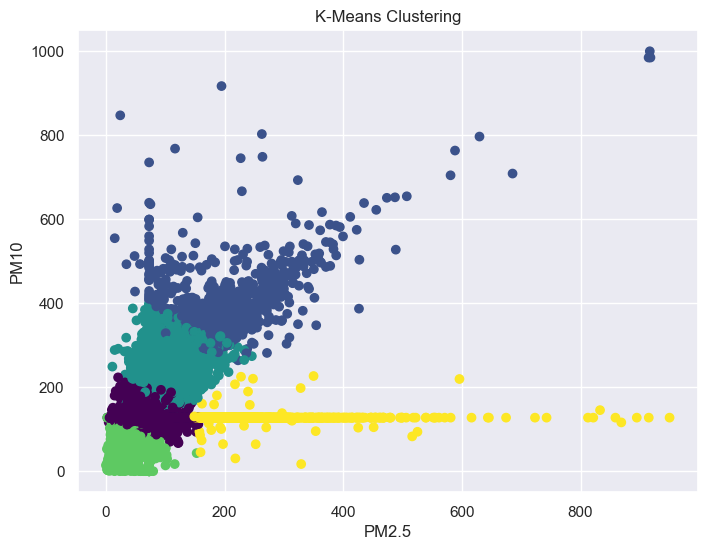

In [127]:
# Drop AQI and Air_quality columns as they are not used for clustering
X = df.drop(columns=['AQI', 'Air_quality'])

# Perform K-Means clustering with k=3 (you can change the number of clusters as needed)
kmeans = KMeans(n_clusters=5,n_init=10, random_state=42)
df['cluster'] = kmeans.fit_predict(X)

# Visualize the clusters (assuming PM2.5 and PM10 are plotted on a scatter plot)
plt.scatter(df['PM2.5'], df['PM10'], c=df['cluster'], cmap='viridis')
plt.xlabel('PM2.5')
plt.ylabel('PM10')
plt.title('K-Means Clustering')
plt.show()

# 2. Principal Component Analysis:

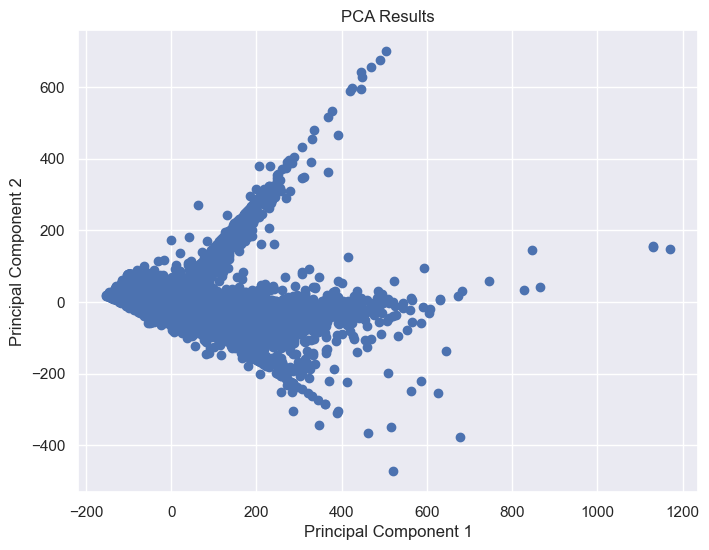

In [128]:
Y = df.drop(columns=['AQI', 'Air_quality'])

# Perform PCA with the number of components you desire (let's say 2 components for visualization)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(Y)

# Create a new DataFrame with the PCA results
pca_df = pd.DataFrame(data=pca_result, columns=['PCA1', 'PCA2'])

# Plot the PCA results (assuming PCA1 and PCA2 are plotted on a scatter plot)
plt.scatter(pca_df['PCA1'], pca_df['PCA2'])
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Results')
plt.show()

# Cross Validation and Fine Tuning:

In [129]:
from sklearn.model_selection import GridSearchCV
rf = RandomForestRegressor()

# Define the hyperparameters grid for GridSearchCV
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10],
}

# Initialize GridSearchCV with the Random Forest model and hyperparameters grid
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)

# Perform cross-validation and find the best hyperparameters
grid_search.fit(x_train, y_train)

# Get the best hyperparameters and the best model
best_params = grid_search.best_params_
best_rf = grid_search.best_estimator_

# ML Flow:

In [131]:
import joblib
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# 1. Print final evaluation metrics for best_rf
y_pred_train = best_rf.predict(x_train)
y_pred_test = best_rf.predict(x_test)

print("Train RMSE:", np.sqrt(mean_squared_error(y_train, y_pred_train)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_test)))
print("R2 Score:", r2_score(y_test, y_pred_test))

# 2. Check exact feature columns expected by the model
print("Model Features:", list(x_train.columns))

# 3. Save the trained model into your 'aqi' workspace folder
joblib.dump(best_rf, "aqi_model.pkl")
print("Saved aqi_model.pkl successfully!")

Train RMSE: 16.679394622719208
Test RMSE: 45.03351315095516
R2 Score: 0.8894159913818115
Model Features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
Saved aqi_model.pkl successfully!


## Hence, Random Forest is the best model with highest Accuracy. So, we will use Random Forest as the Regression Model.

# Random Forest:

In [132]:
# Training the model:
Best_Model_RF = RandomForestRegressor(n_estimators = 500, random_state = 0)
Best_Model_RF.fit(x_train,y_train)
Best_Model_RF_predict = Best_Model_RF.predict(x_test)

# Model Evaluation:
# Error Estimation Methods

# Test Data prediction

rmse_r = sqrt(metrics.mean_squared_error(y_test, Best_Model_RF_predict))
mae_r = metrics.mean_absolute_error(y_test, Best_Model_RF_predict)
r2_r = metrics.r2_score(y_test,Best_Model_RF_predict)

# Training Data Prediction

# ----- random forest regression -----
rf_ytp_rms = sqrt(metrics.mean_squared_error(y_train, Best_Model_RF.predict(x_train)))
rf_ytp_ma = metrics.mean_absolute_error(y_train, Best_Model_RF.predict(x_train))
rf_ytp_r = metrics.r2_score(y_train, Best_Model_RF.predict(x_train))


# RESULT

print("Evaluating on Training Data:")
print("Models                   \tR^2\tRMSE\tMAE")
print("Random Forest Regression \t{0:.4f}\t{1:.4f}\t{2:.4f}".format(rf_ytp_r,rf_ytp_rms,rf_ytp_ma))
print("\n")
print("Evaluating on Testing Data:")
print("Models                   \tR^2\tRMSE\tMAE")
print("Random Forest Regression \t{0:.4f}\t{1:.4f}\t{2:.4f}".format(r2_r,rmse_r,mae_r))

Evaluating on Training Data:
Models                   	R^2	RMSE	MAE
Random Forest Regression 	0.9856	16.5891	7.5351


Evaluating on Testing Data:
Models                   	R^2	RMSE	MAE
Random Forest Regression 	0.8902	44.8659	19.5856


# Model Deployment:

In [133]:
import pickle
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import pandas as pd

df = df
# Split the data into training and testing sets
y = df["AQI"]
x = df[['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2','O3', 'Benzene', 'Toluene', 'Xylene']]

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.25,random_state=0)
print(x_train.shape,x_test.shape,y_train.shape,y_test.shape)

# Training the model:
best_model_rf = RandomForestRegressor(n_estimators=500, random_state=0)
best_model_rf.fit(x_train, y_train)

# Save the trained model to a pickle file
model_filename = 'random_forest_model.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(best_model_rf, file)


(19166, 12) (6389, 12) (19166,) (6389,)
